# 05 · DAG and Bayesian network
**Owner:** Jagruthi Pulumati

1. Turn the predicted "X directly causes Y" claims into one DAG per test premise (no self-loops, no cycles)
2. Measure **edge precision** against the true edges
3. Fit a **pgmpy Bayesian network** and answer intervention questions like P(Y | do(X))

`build_dag` and `do_effect` live in `src/c2c/bayes.py` and are tested in `tests/test_bayes.py`.

In [1]:
# ─── IMPORTS ─────
import sys
import itertools
import warnings
warnings.filterwarnings("ignore")   # hide pgmpy deprecation messages

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator
from pgmpy.factors.discrete import TabularCPD

sys.path.insert(0, "../src")
from c2c.bayes import build_dag, do_effect

In [2]:
# ─── LOAD DATA ─────
predictions = pd.read_csv("../data/processed/test_predictions.csv")
graphs = pd.read_csv("../data/processed/premise_graphs.csv").fillna("")
graphs = graphs[graphs["split"] == "test"]
predictions.head()

,premise_id,hypothesis,template,relation,x,y,label,proba,pred
0,2358,"There exists at least one collider (i.e., comm...",has_collider,collider,A,B,0,0.336667,0
1,2358,A directly causes B.,parent,direct_cause,A,B,0,0.062241,0
2,2358,"A is a cause for B, but not a direct one.",non-child descendant,indirect_cause,A,B,0,0.040277,0
3,2358,B directly causes A.,child,direct_cause,B,A,0,0.060087,0
4,2358,B causes something else which causes A.,non-parent ancestor,indirect_cause,B,A,0,0.030254,0


In [3]:
# ─── STEP 1: CANDIDATE EDGES ─────
# every "X directly causes Y" claim predicted as valid becomes an edge X -> Y
direct = predictions[predictions["relation"] == "direct_cause"]
edges = direct[direct["pred"] == 1].sort_values("proba", ascending=False)   # most confident first
print(len(direct), "direct-cause claims,", len(edges), "predicted valid")

388 direct-cause claims, 73 predicted valid


In [4]:
# ─── STEP 2: BUILD THE DAGS ─────
# build_dag skips an edge if it is a self-loop, uses a variable not in the premise, or would make a cycle
dags = {}
for premise_id, variables in zip(graphs["premise_id"], graphs["variables"]):
    dags[premise_id] = build_dag(variables.split(", "), edges[edges["premise_id"] == premise_id])

# every graph should be a DAG
print(len(dags), "graphs, all DAGs:", all(nx.is_directed_acyclic_graph(dag) for dag in dags.values()))

21 graphs, all DAGs: True


In [5]:
# check the rules with some bad edges
bad = pd.DataFrame({"x": ["A", "B", "C", "B", "A"], "y": ["B", "C", "A", "B", "G"]})
bad_dag = build_dag(["A", "B", "C"], bad)
bad_dag.edges

OutEdgeView([('A', 'B'), ('B', 'C')])

C → A (makes a cycle), B → B (self-loop) and A → G (G is not in the premise) are all skipped.

In [6]:
# ─── STEP 3: EDGE PRECISION ─────
# the true edges are the "directly causes" claims with label 1
edges["kept"] = edges.apply(lambda r: dags[r["premise_id"]].has_edge(r["x"], r["y"]), axis=1)
kept = edges[edges["kept"]]

edge_precision = kept["label"].mean()
edge_recall = kept["label"].sum() / direct["label"].sum()
print("edges drawn:", len(kept), " correct:", kept["label"].sum(), " true edges:", direct["label"].sum())
print("edge precision:", round(edge_precision, 3), " edge recall:", round(edge_recall, 3))

edges drawn: 73  correct: 65  true edges: 65
edge precision: 0.89  edge recall: 1.0


In [7]:
# the same against the PC graph from notebook 02
pc_edges = graphs.set_index("premise_id")["directed_edges"]
kept_in_pc = kept.apply(lambda r: f"{r['x']}->{r['y']}" in pc_edges[r["premise_id"]], axis=1)
print("edge precision vs PC:", round(kept_in_pc.mean(), 3))

edge precision vs PC: 1.0


The extra edges are ones PC supports but the dataset labels as 0, so precision against the PC graph is higher.

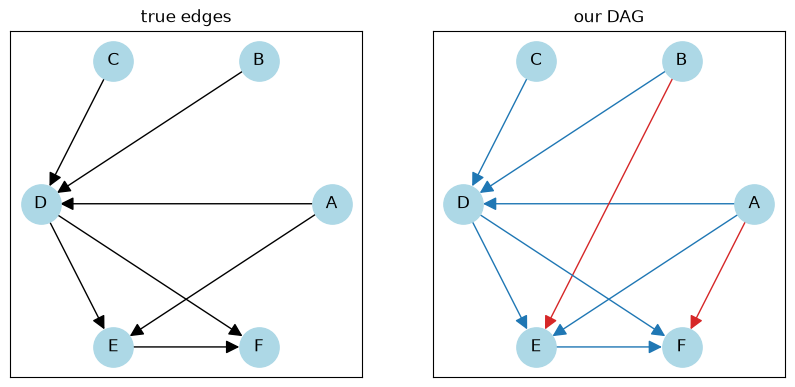

In [8]:
# one predicted DAG next to the true edges (red = an edge we drew that is not true)
wrong_edges = kept[kept["label"] == 0]
premise_id = wrong_edges["premise_id"].iloc[0]
true_edges = direct[(direct["premise_id"] == premise_id) & (direct["label"] == 1)]

our_dag = dags[premise_id]
true_dag = nx.DiGraph()
true_dag.add_nodes_from(our_dag.nodes)
true_dag.add_edges_from(zip(true_edges["x"], true_edges["y"]))

pos = nx.circular_layout(sorted(our_dag.nodes))
colors = ["tab:blue" if true_dag.has_edge(x, y) else "tab:red" for x, y in our_dag.edges]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
nx.draw_networkx(true_dag, pos, ax=axes[0], node_color="lightblue", node_size=800, arrowsize=20)
axes[0].set_title("true edges")
nx.draw_networkx(our_dag, pos, ax=axes[1], node_color="lightblue", node_size=800, arrowsize=20, edge_color=colors)
axes[1].set_title("our DAG")
plt.savefig("../report/figures/dag_vs_truth.png", dpi=150, bbox_inches="tight")
plt.show()

## Bayesian network
Corr2Cause has no numbers, so we:
1. take a graph, give it random probability tables and simulate 5,000 rows
2. fit **our** DAG on that data with pgmpy
3. compare the intervention answers from our network with the true one

In [9]:
# ─── STEP 4: INTERVENTION EFFECT ─────
# do_effect(model, X, Y) = P(Y=1 | do(X=1)) - P(Y=1 | do(X=0)), and 0 if Y is not downstream of X

In [10]:
# ─── STEP 5: WHY DIRECTION MATTERS ─────
# true graph A -> B -> C, where each variable strongly follows its parent
truth = DiscreteBayesianNetwork([("A", "B"), ("B", "C")])
cpd_a = TabularCPD("A", 2, [[0.5], [0.5]])
cpd_b = TabularCPD("B", 2, [[0.9, 0.2], [0.1, 0.8]], evidence=["A"], evidence_card=[2])
cpd_c = TabularCPD("C", 2, [[0.9, 0.2], [0.1, 0.8]], evidence=["B"], evidence_card=[2])
truth.add_cpds(cpd_a, cpd_b, cpd_c)
sim = truth.simulate(5000, seed=42, show_progress=False)
sim.head()

,A,C,B
0,0,0,0
1,1,1,1
2,1,1,1
3,1,0,1
4,0,0,0


In [11]:
# fit the correct graph and the reversed graph on the same data
right = DiscreteBayesianNetwork([("A", "B"), ("B", "C")])
right.fit(sim, estimator=DiscreteBayesianEstimator())

wrong = DiscreteBayesianNetwork([("C", "B"), ("B", "A")])
wrong.fit(sim, estimator=DiscreteBayesianEstimator())

pd.DataFrame({
    "do(A) on C": [do_effect(truth, "A", "C"), do_effect(right, "A", "C"), do_effect(wrong, "A", "C")],
    "do(C) on A": [do_effect(truth, "C", "A"), do_effect(right, "C", "A"), do_effect(wrong, "C", "A")],
}, index=["truth", "correct graph", "reversed graph"]).round(3)

,do(A) on C,do(C) on A
truth,0.490,0.000
correct graph,0.498,0.000
reversed graph,0.000,0.514


In A → B → C, forcing A changes C but forcing C does not change A. The reversed graph fits the same data but gets this wrong.

In [12]:
# ─── STEP 6: INTERVENTION QUERIES ON TEST PREMISES ─────
# premises where PC knows the full graph (only one possible DAG), so the true answers are known
known = graphs[(graphs["mec_size"] == 1) & (graphs["directed_edges"] != "")]


def fit(edges, nodes, data):
    model = DiscreteBayesianNetwork(list(edges))
    model.add_nodes_from(nodes)
    model.fit(data, estimator=DiscreteBayesianEstimator())
    return model


rows = []
for premise_id, variables, directed_edges in zip(known["premise_id"], known["variables"], known["directed_edges"]):
    nodes = variables.split(", ")
    true_edges = [tuple(e.split("->")) for e in directed_edges.split(";")]

    # true network with its own random probabilities (seed = premise id), and 5,000 rows simulated from it
    truth = DiscreteBayesianNetwork(true_edges)
    truth.add_nodes_from(nodes)
    truth.get_random_cpds(n_states=2, inplace=True, seed=premise_id)
    sim = truth.simulate(5000, seed=premise_id, show_progress=False)

    # our predicted DAG, and the same DAG with every arrow reversed, both fitted on the same data
    ours = fit(dags[premise_id].edges, nodes, sim)
    reversed_dag = fit([(b, a) for a, b in dags[premise_id].edges], nodes, sim)

    # ask about every ordered pair, in both directions
    for cause, effect in itertools.permutations(nodes, 2):
        rows.append({"premise": premise_id, "query": f"do({cause}) on {effect}",
                     "true effect": do_effect(truth, cause, effect),
                     "our graph": do_effect(ours, cause, effect),
                     "reversed graph": do_effect(reversed_dag, cause, effect),
                     "empty graph": 0.0,
                     "true path": effect in nx.descendants(nx.DiGraph(true_edges), cause),
                     "our path": effect in nx.descendants(dags[premise_id], cause),
                     "reversed path": cause in nx.descendants(dags[premise_id], effect)})

queries = pd.DataFrame(rows)
print(len(queries), "queries on", queries["premise"].nunique(), "premises,",
      queries["true path"].sum(), "with a real effect")
queries.head(10).round(3)

96 queries on 5 premises, 32 with a real effect


,premise,query,true effect,our graph,reversed graph,empty graph,true path,our path,reversed path
0,2359,do(A) on B,0.000,0.000,0.000,0.0,False,False,False
1,2359,do(A) on C,-0.034,-0.032,0.000,0.0,True,True,False
2,2359,do(B) on A,0.000,0.000,0.000,0.0,False,False,False
3,2359,do(B) on C,0.135,0.122,0.000,0.0,True,True,False
4,2359,do(C) on A,0.000,0.000,-0.078,0.0,False,False,True
5,2359,do(C) on B,0.000,0.000,0.317,0.0,False,False,True
6,2346,do(A) on B,0.000,0.000,0.000,0.0,False,False,False
7,2346,do(A) on C,-0.306,-0.310,0.000,0.0,True,True,False
8,2346,do(A) on D,0.157,0.000,0.000,0.0,True,False,False
9,2346,do(A) on E,-0.458,-0.447,0.000,0.0,True,True,False


In [13]:
# a query matches if the graph gets BOTH right:
#   1. whether there is an effect at all (a directed path from cause to effect), and
#   2. its size, within 0.05
# without rule 1, a tiny true effect (e.g. 0.046) would "match" a graph that has no arrow at all
def matches(graph_effect, graph_has_path):
    same_answer = graph_has_path == queries["true path"]
    return same_answer & ((queries["true effect"] - graph_effect).abs() <= 0.05)


summary = {}
for name, has_path in [("our graph", queries["our path"]),
                       ("reversed graph", queries["reversed path"]),
                       ("empty graph", pd.Series(False, index=queries.index))]:
    ok = matches(queries[name], has_path)
    summary[name] = {
        "all queries": f"{ok.sum()} / {len(ok)}",
        "queries with a real effect": f"{ok[queries['true path']].sum()} / {queries['true path'].sum()}",
        "mean |error|": (queries[name] - queries["true effect"]).abs().mean().round(3),
    }
pd.DataFrame(summary).T

,all queries,queries with a real effect,mean |error|
our graph,92 / 96,28 / 32,0.011
reversed graph,36 / 96,0 / 32,0.126
empty graph,64 / 96,0 / 32,0.064


Our DAGs answer the intervention queries correctly, including the ones with a real effect. The baselines show the
check is not trivial: the empty graph gets every "is there an effect?" query wrong where an effect exists, and the
reversed graph puts effects in the wrong direction. So better edge extraction leads directly to better causal answers.